# Do Google Play categories cluster in the embedding space? — clearer views

This copy of the projection notebook joins RICO screen embeddings with Google Play categories, averages screens into one vector per app, and emphasizes views that reveal overlap as well as separation:

- **UMAP overview**: a single shared projection with category centroids labelled.
- **UMAP small multiples**: every category is highlighted against the same faint background, with density contours and a centroid.
- **Neighborhood purity**: category-level evidence measured in the original embedding space.
- **PCA and t-SNE**: secondary projection diagnostics rather than the main evidence.

The primary evidence is computed in the original normalized embedding space: category neighborhood purity, its label-permutation baseline, and the cosine silhouette score. The projections are supporting visualizations. Each dot is one app so apps with many RICO screens do not dominate the analysis.

In [1]:
from __future__ import annotations

import ast
import csv
import json
import re
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm

sns.set_theme(context="paper", style="whitegrid", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 300})

C:\Users\Jonathan\Dev\screen2vec-revisited\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuration

The default paths match the local RICO checkout. `EMBEDDINGS_PATH` may be a Hugging Face dataset saved to disk, a CSV/Parquet/JSONL table, a single NumPy file, or a directory of per-screen `.npy`/`.npz` files. For tabular data, the preferred columns are `screen_id` and `embeddings_64x4096_avg`; common alternatives are detected automatically.

The balanced app sample makes colors readable and keeps t-SNE practical. Raise the limits for a final run if memory and runtime permit.

In [2]:
RANDOM_STATE = 42
RICO_ROOT = Path(r"C:\Users\Jonathan\Dev\rico-data")
SCREEN2VEC_ROOT = Path(r"C:\Users\Jonathan\Dev\screen2vec-revisited")
EMBEDDINGS_PATH = SCREEN2VEC_ROOT / "embeddings_64x4096_avg"
METADATA_PATH = RICO_ROOT / "data" / "play_store_metadata" / "app_details_enriched.csv"
LAYOUTS_DIR = RICO_ROOT / "data" / "layouts"
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "_screen2vec.tex").exists()), Path.cwd())
OUTPUT_DIR = PROJECT_ROOT / "graphics" / "category_embedding_cluster_views"

TOP_N_CATEGORIES = 12
MAX_APPS_PER_CATEGORY = 250
MAX_SCREENS_PER_APP = 5
MIN_APPS_PER_CATEGORY = 25
PCA_PRECOMPONENTS = 50
K_NEIGHBORS = 10
N_PERMUTATIONS = 500

for required in (EMBEDDINGS_PATH, METADATA_PATH, LAYOUTS_DIR):
    if not required.exists():
        raise FileNotFoundError(f"Missing required input: {required}")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Embeddings: {EMBEDDINGS_PATH}")
print(f"Metadata:   {METADATA_PATH}")
print(f"Outputs:    {OUTPUT_DIR.resolve()}")

Embeddings: C:\Users\Jonathan\Dev\screen2vec-revisited\embeddings_64x4096_avg
Metadata:   C:\Users\Jonathan\Dev\rico-data\data\play_store_metadata\app_details_enriched.csv
Outputs:    C:\Users\Jonathan\Dev\screen2vec-revisited\graphics\category_embedding_cluster_views


## Join RICO screens to app categories

A RICO layout stores the package in the top-level `activity_name` field as `package/activity`. Reading only the start of each JSON is much faster than parsing the complete view hierarchy. We first select categories and apps, then load embeddings only for the selected screen IDs.

In [3]:
ACTIVITY_RE = re.compile(r'"activity_name"\s*:\s*"([^"]+)"')

def package_from_layout(path: Path) -> str | None:
    with path.open("r", encoding="utf-8", errors="replace") as handle:
        prefix = handle.read(16_384)
    match = ACTIVITY_RE.search(prefix)
    return match.group(1).split("/", 1)[0] if match else None

metadata = pd.read_csv(
    METADATA_PATH,
    usecols=["App Package Name", "Play Store Name", "Category"],
    dtype=str,
).dropna(subset=["App Package Name", "Category"])
metadata = metadata.drop_duplicates("App Package Name", keep="first")
package_to_category = metadata.set_index("App Package Name")["Category"].to_dict()
package_to_name = metadata.set_index("App Package Name")["Play Store Name"].to_dict()

layout_rows = []
layout_paths = sorted(LAYOUTS_DIR.glob("*.json"), key=lambda p: p.stem)
for path in tqdm(layout_paths, desc="Reading layout identities"):
    package = package_from_layout(path)
    category = package_to_category.get(package)
    if category:
        layout_rows.append((path.stem, package, category))

screen_map = pd.DataFrame(layout_rows, columns=["screen_id", "package", "category"])
app_counts = screen_map.drop_duplicates("package").groupby("category").size().sort_values(ascending=False)
eligible = app_counts[app_counts >= MIN_APPS_PER_CATEGORY].head(TOP_N_CATEGORIES).index
screen_map = screen_map[screen_map["category"].isin(eligible)].copy()

rng = np.random.default_rng(RANDOM_STATE)
selected_apps = []
for category, group in screen_map[["package", "category"]].drop_duplicates().groupby("category"):
    apps = group["package"].to_numpy()
    chosen = rng.choice(apps, size=min(MAX_APPS_PER_CATEGORY, len(apps)), replace=False)
    selected_apps.extend(chosen.tolist())

selected_screens = (
    screen_map[screen_map["package"].isin(selected_apps)]
    .sample(frac=1, random_state=RANDOM_STATE)
    .groupby("package", group_keys=False)
    .head(MAX_SCREENS_PER_APP)
    .reset_index(drop=True)
)
selected_screens["package"] = selected_screens["package"].astype(str)
selected_screens["category"] = selected_screens["package"].map(package_to_category)
selected_screens["app_name"] = selected_screens["package"].map(package_to_name)
selected_screens = selected_screens[["screen_id", "package", "app_name", "category"]]

display(app_counts.rename("apps available").to_frame().head(TOP_N_CATEGORIES))
print(f"Selected {selected_screens['package'].nunique():,} apps and {len(selected_screens):,} screens.")

Reading layout identities: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 66261/66261 [00:09<00:00, 7098.02it/s]


,apps available
category,
Entertainment,932
Social,588
Communication,584
Lifestyle,557
Books & Reference,521
Education,501
Travel & Local,431
Health & Fitness,429
Shopping,429


Selected 3,000 apps and 10,837 screens.


## Load the selected embeddings

The loader converts an array shaped `(64, 4096)` to one 4096-dimensional vector by averaging across the first axis. Already averaged vectors are left unchanged. It checks for duplicate screen IDs and inconsistent dimensionality before analysis.

In [4]:
ID_COLUMNS = ("screen_id", "id", "screen", "path", "file", "filename", "source")
VECTOR_COLUMNS = ("embeddings_64x4096_avg", "embedding", "embeddings", "vector", "features")

def canonical_screen_id(value) -> str:
    return Path(str(value).replace("\\", "/")).stem

def as_vector(value) -> np.ndarray:
    if isinstance(value, str):
        text = value.strip()
        try:
            value = json.loads(text)
        except json.JSONDecodeError:
            try:
                value = ast.literal_eval(text)
            except (SyntaxError, ValueError):
                value = np.fromstring(text.strip("[]"), sep=",")
    array = np.asarray(value, dtype=np.float32).squeeze()
    if array.ndim == 2:
        array = array.mean(axis=0)
    if array.ndim != 1:
        raise ValueError(f"Expected a vector or matrix, got shape {array.shape}")
    return array

def columns_for(frame: pd.DataFrame) -> tuple[str, str]:
    id_col = next((c for c in ID_COLUMNS if c in frame.columns), None)
    vector_col = next((c for c in VECTOR_COLUMNS if c in frame.columns), None)
    if id_col is None or vector_col is None:
        if frame.shape[1] == 2:
            return frame.columns[0], frame.columns[1]
        raise ValueError(f"Could not identify ID/vector columns. Found: {frame.columns.tolist()}")
    return id_col, vector_col

def rows_from_frame(frame: pd.DataFrame, wanted: set[str]):
    id_col, vector_col = columns_for(frame)
    ids = frame[id_col].map(canonical_screen_id)
    for screen_id, value in zip(ids, frame[vector_col]):
        if screen_id in wanted:
            yield screen_id, as_vector(value)

def load_table(path: Path, wanted: set[str]):
    suffix = path.suffix.lower()
    if suffix == ".parquet":
        yield from rows_from_frame(pd.read_parquet(path), wanted)
    elif suffix in {".jsonl", ".json"}:
        yield from rows_from_frame(pd.read_json(path, lines=suffix == ".jsonl"), wanted)
    elif suffix == ".csv":
        with path.open("r", encoding="utf-8", errors="replace", newline="") as handle:
            first = next(csv.reader(handle))
        has_named_columns = any(name in first for name in (*ID_COLUMNS, *VECTOR_COLUMNS))
        kwargs = {} if has_named_columns else {"header": None, "names": ["screen_id", "embedding"]}
        for chunk in pd.read_csv(path, chunksize=1_000, **kwargs):
            yield from rows_from_frame(chunk, wanted)
    else:
        raise ValueError(f"Unsupported table format: {path}")

def load_array_file(path: Path) -> np.ndarray:
    loaded = np.load(path, allow_pickle=False)
    if isinstance(loaded, np.lib.npyio.NpzFile):
        preferred = next((key for key in VECTOR_COLUMNS if key in loaded.files), None)
        if preferred is None and len(loaded.files) == 1:
            preferred = loaded.files[0]
        if preferred is None:
            loaded.close()
            raise ValueError(f"Cannot choose a vector from {path}; keys={loaded.files}")
        array = loaded[preferred]
        loaded.close()
        return as_vector(array)
    return as_vector(loaded)

def rows_from_dataset(dataset, wanted: set[str]):
    columns = dataset.column_names
    id_col = next((c for c in ID_COLUMNS if c in columns), None)
    vector_col = next((c for c in VECTOR_COLUMNS if c in columns), None)
    if id_col is None or vector_col is None:
        raise ValueError(f"Could not identify ID/vector columns. Found: {columns}")
    for row in dataset:
        screen_id = canonical_screen_id(row[id_col])
        if screen_id in wanted:
            yield screen_id, as_vector(row[vector_col])

def rows_from_array_files(files: list[Path], wanted: set[str]):
    selected = [file for file in files if canonical_screen_id(file.stem) in wanted]
    def load_one(file: Path):
        return canonical_screen_id(file.stem), load_array_file(file)
    with ThreadPoolExecutor() as executor:
        yield from executor.map(load_one, selected)

def load_selected_embeddings(path: Path, wanted: set[str]) -> tuple[list[str], np.ndarray]:
    rows = {}
    table_suffixes = {".csv", ".parquet", ".json", ".jsonl"}
    if path.is_file() and path.suffix.lower() in table_suffixes:
        iterator = load_table(path, wanted)
    elif path.is_file() and path.suffix.lower() in {".npy", ".npz"}:
        archive = np.load(path, allow_pickle=False)
        if isinstance(archive, np.lib.npyio.NpzFile):
            iterator = ((canonical_screen_id(k), as_vector(archive[k])) for k in archive.files)
        else:
            raise ValueError("A single .npy needs IDs; use an .npz keyed by screen ID or per-screen files.")
    elif path.is_dir() and (path / "dataset_info.json").exists():
        from datasets import load_from_disk
        dataset = load_from_disk(str(path))
        if hasattr(dataset, "values"):
            parts = list(dataset.values())
            dataset = parts[0] if len(parts) == 1 else __import__("datasets").concatenate_datasets(parts)
        iterator = rows_from_dataset(dataset, wanted)
    elif path.is_dir():
        tables = [p for p in path.rglob("*") if p.suffix.lower() in table_suffixes]
        arrays = [p for p in path.rglob("*") if p.suffix.lower() in {".npy", ".npz"}]
        if tables:
            iterator = (row for table in tables for row in load_table(table, wanted))
        elif arrays:
            iterator = rows_from_array_files(arrays, wanted)
        else:
            raise FileNotFoundError(f"No supported embedding files found under {path}")
    else:
        raise FileNotFoundError(path)

    for screen_id, vector in tqdm(iterator, desc="Loading selected embeddings"):
        if screen_id in wanted and screen_id not in rows:
            rows[screen_id] = vector
    if not rows:
        raise ValueError("No embeddings matched the selected RICO screen IDs. Check the ID column and paths.")
    dimensions = Counter(vector.size for vector in rows.values())
    if len(dimensions) != 1:
        raise ValueError(f"Inconsistent embedding dimensions: {dimensions}")
    ids = list(rows)
    return ids, np.stack([rows[screen_id] for screen_id in ids]).astype(np.float32)

wanted_ids = set(selected_screens["screen_id"])
screen_ids, screen_vectors = load_selected_embeddings(EMBEDDINGS_PATH, wanted_ids)
print(f"Loaded {len(screen_ids):,}/{len(wanted_ids):,} selected screens; shape={screen_vectors.shape}.")

Loading selected embeddings: 10837it [00:14, 746.03it/s]


Loaded 10,837/10,837 selected screens; shape=(10837, 4096).


## Average screen embeddings per app

Each screen vector is L2-normalized before averaging, and each app mean is normalized again. This treats cosine similarity as the relevant geometry and gives every app equal weight. Categories that fall below the minimum after missing embeddings are removed.

In [5]:
loaded = pd.DataFrame({"screen_id": screen_ids, "embedding": list(normalize(screen_vectors))})
joined = selected_screens.merge(loaded, on="screen_id", how="inner", validate="one_to_one")

app_rows = []
for package, group in joined.groupby("package", sort=False):
    app_rows.append({
        "package": package,
        "app_name": group["app_name"].iloc[0],
        "category": group["category"].iloc[0],
        "n_screens": len(group),
        "embedding": np.stack(group["embedding"]).mean(axis=0),
    })
apps = pd.DataFrame(app_rows)
valid_categories = apps["category"].value_counts()
valid_categories = valid_categories[valid_categories >= MIN_APPS_PER_CATEGORY].index
apps = apps[apps["category"].isin(valid_categories)].reset_index(drop=True)
X = normalize(np.stack(apps["embedding"])).astype(np.float32)
labels = apps["category"].to_numpy()

display(apps.groupby("category").agg(apps=("package", "size"), screens=("n_screens", "sum")).sort_values("apps", ascending=False))
print(f"Final analysis matrix: {X.shape[0]:,} apps × {X.shape[1]:,} dimensions")

,apps,screens
category,,
Books & Reference,250,933
Communication,250,858
Education,250,866
Entertainment,250,826
Health & Fitness,250,943
Lifestyle,250,871
Music & Audio,250,894
News & Magazines,250,1025
Shopping,250,985


Final analysis matrix: 3,000 apps × 4,096 dimensions


## Quantify category structure in the original embedding space

Neighborhood purity is the fraction of each app's nearest neighbors that share its category. The chance baseline accounts for the observed category frequencies. The permutation test holds the embedding neighborhoods fixed and randomly shuffles category labels.

In [6]:
k = min(K_NEIGHBORS, len(apps) - 1)
neighbors = NearestNeighbors(n_neighbors=k + 1, metric="cosine").fit(X)
neighbor_indices = neighbors.kneighbors(X, n_neighbors=k + 1, return_distance=False)[:, 1:]
point_purity = (labels[neighbor_indices] == labels[:, None]).mean(axis=1)
observed_purity = point_purity.mean()
frequencies = pd.Series(labels).value_counts(normalize=True)
chance_purity = float((frequencies ** 2).sum())

rng = np.random.default_rng(RANDOM_STATE)
null_purity = np.empty(N_PERMUTATIONS)
for i in range(N_PERMUTATIONS):
    shuffled = rng.permutation(labels)
    null_purity[i] = (shuffled[neighbor_indices] == shuffled[:, None]).mean()
p_value = (1 + np.count_nonzero(null_purity >= observed_purity)) / (N_PERMUTATIONS + 1)
silhouette = silhouette_score(X, labels, metric="cosine", sample_size=min(5_000, len(X)), random_state=RANDOM_STATE)

metrics = pd.DataFrame({
    "metric": [f"{k}-NN category purity", "frequency chance purity", "permutation mean purity", "permutation p-value", "cosine silhouette"],
    "value": [observed_purity, chance_purity, null_purity.mean(), p_value, silhouette],
})
category_metrics = (
    pd.DataFrame({"category": labels, "neighbor_purity": point_purity})
    .groupby("category")
    .agg(apps=("neighbor_purity", "size"), neighbor_purity=("neighbor_purity", "mean"))
    .sort_values("neighbor_purity", ascending=False)
)
category_metrics["chance_purity"] = (category_metrics["apps"] - 1) / (len(apps) - 1)
display(metrics.style.format({"value": "{:.4f}"}))
display(category_metrics.style.format({"neighbor_purity": "{:.3f}", "chance_purity": "{:.3f}"}))
metrics.to_csv(OUTPUT_DIR / "category_structure_metrics.csv", index=False)
category_metrics.to_csv(OUTPUT_DIR / "category_neighborhood_purity.csv")

,metric,value
0,10-NN category purity,0.4282
1,frequency chance purity,0.0833
2,permutation mean purity,0.0830
3,permutation p-value,0.0020
4,cosine silhouette,-0.0503


,apps,neighbor_purity,chance_purity
category,,,
Weather,250,0.709,0.083
News & Magazines,250,0.637,0.083
Music & Audio,250,0.634,0.083
Shopping,250,0.529,0.083
Health & Fitness,250,0.482,0.083
Books & Reference,250,0.399,0.083
Communication,250,0.381,0.083
Travel & Local,250,0.366,0.083
Social,250,0.347,0.083


## Compute PCA, t-SNE, and UMAP

t-SNE and UMAP operate on a 50-component PCA representation for speed and denoising. All random seeds are fixed. A shared palette keeps categories consistent across panels.

In [7]:
n_precomponents = min(PCA_PRECOMPONENTS, X.shape[0] - 1, X.shape[1])
pca_pre = PCA(n_components=n_precomponents, random_state=RANDOM_STATE)
X_pca = pca_pre.fit_transform(X)
pca_2d = X_pca[:, :2]

perplexity = min(30, max(5, (len(X) - 1) // 3))
tsne_2d = TSNE(
    n_components=2, perplexity=perplexity, init="pca", learning_rate="auto",
    max_iter=1_000, random_state=RANDOM_STATE,
).fit_transform(X_pca)

umap_2d = umap.UMAP(
    n_components=2, n_neighbors=30, min_dist=0.15, metric="euclidean",
    random_state=RANDOM_STATE, n_jobs=1,
).fit_transform(X_pca)

projection = apps.drop(columns="embedding").copy()
projection[["pca_1", "pca_2"]] = pca_2d
projection[["tsne_1", "tsne_2"]] = tsne_2d
projection[["umap_1", "umap_2"]] = umap_2d
projection.to_csv(OUTPUT_DIR / "app_category_projections.csv", index=False)
print(f"PC1 + PC2 explain {pca_pre.explained_variance_ratio_[:2].sum():.1%} of variance.")

PC1 + PC2 explain 38.3% of variance.


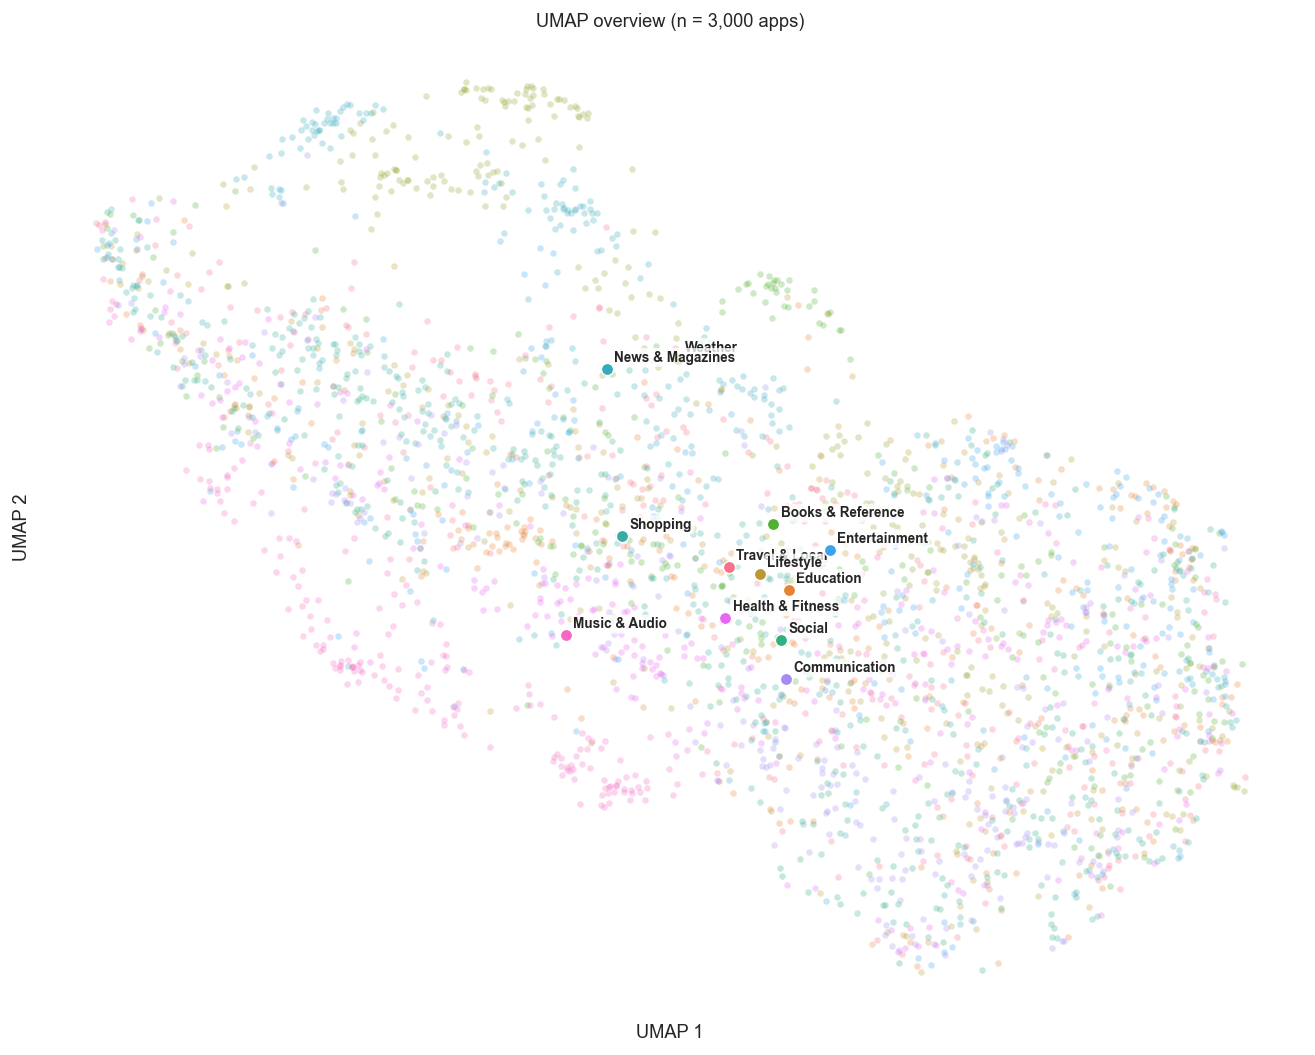

In [8]:
category_order = projection["category"].value_counts().index.tolist()
palette = dict(zip(category_order, sns.color_palette("husl", len(category_order))))
centroids = projection.groupby("category")[["umap_1", "umap_2"]].mean()

fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
for category in category_order:
    points = projection[projection["category"] == category]
    ax.scatter(
        points["umap_1"], points["umap_2"], s=13, alpha=0.28,
        color=palette[category], linewidths=0, rasterized=True,
    )
for category, (x, y) in centroids.loc[category_order].iterrows():
    ax.scatter(x, y, s=46, color=palette[category], edgecolor="white", linewidth=0.8, zorder=3)
    ax.annotate(
        category, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=7.5,
        weight="semibold", bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.78},
    )
ax.set(title=f"UMAP overview (n = {len(projection):,} apps)", xlabel="UMAP 1", ylabel="UMAP 2")
ax.set_xticks([])
ax.set_yticks([])
sns.despine(ax=ax, left=True, bottom=True)
fig.savefig(OUTPUT_DIR / "app_categories_umap_overview.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "app_categories_umap_overview.pdf", bbox_inches="tight")
plt.show()

## Category-highlight UMAP small multiples

Every panel uses the same coordinates and axis limits. All apps remain visible in gray; the named category is highlighted, its mean location is marked with a star, and KDE contours summarize its denser regions. This makes overlap and outliers visible without implying hard cluster boundaries.

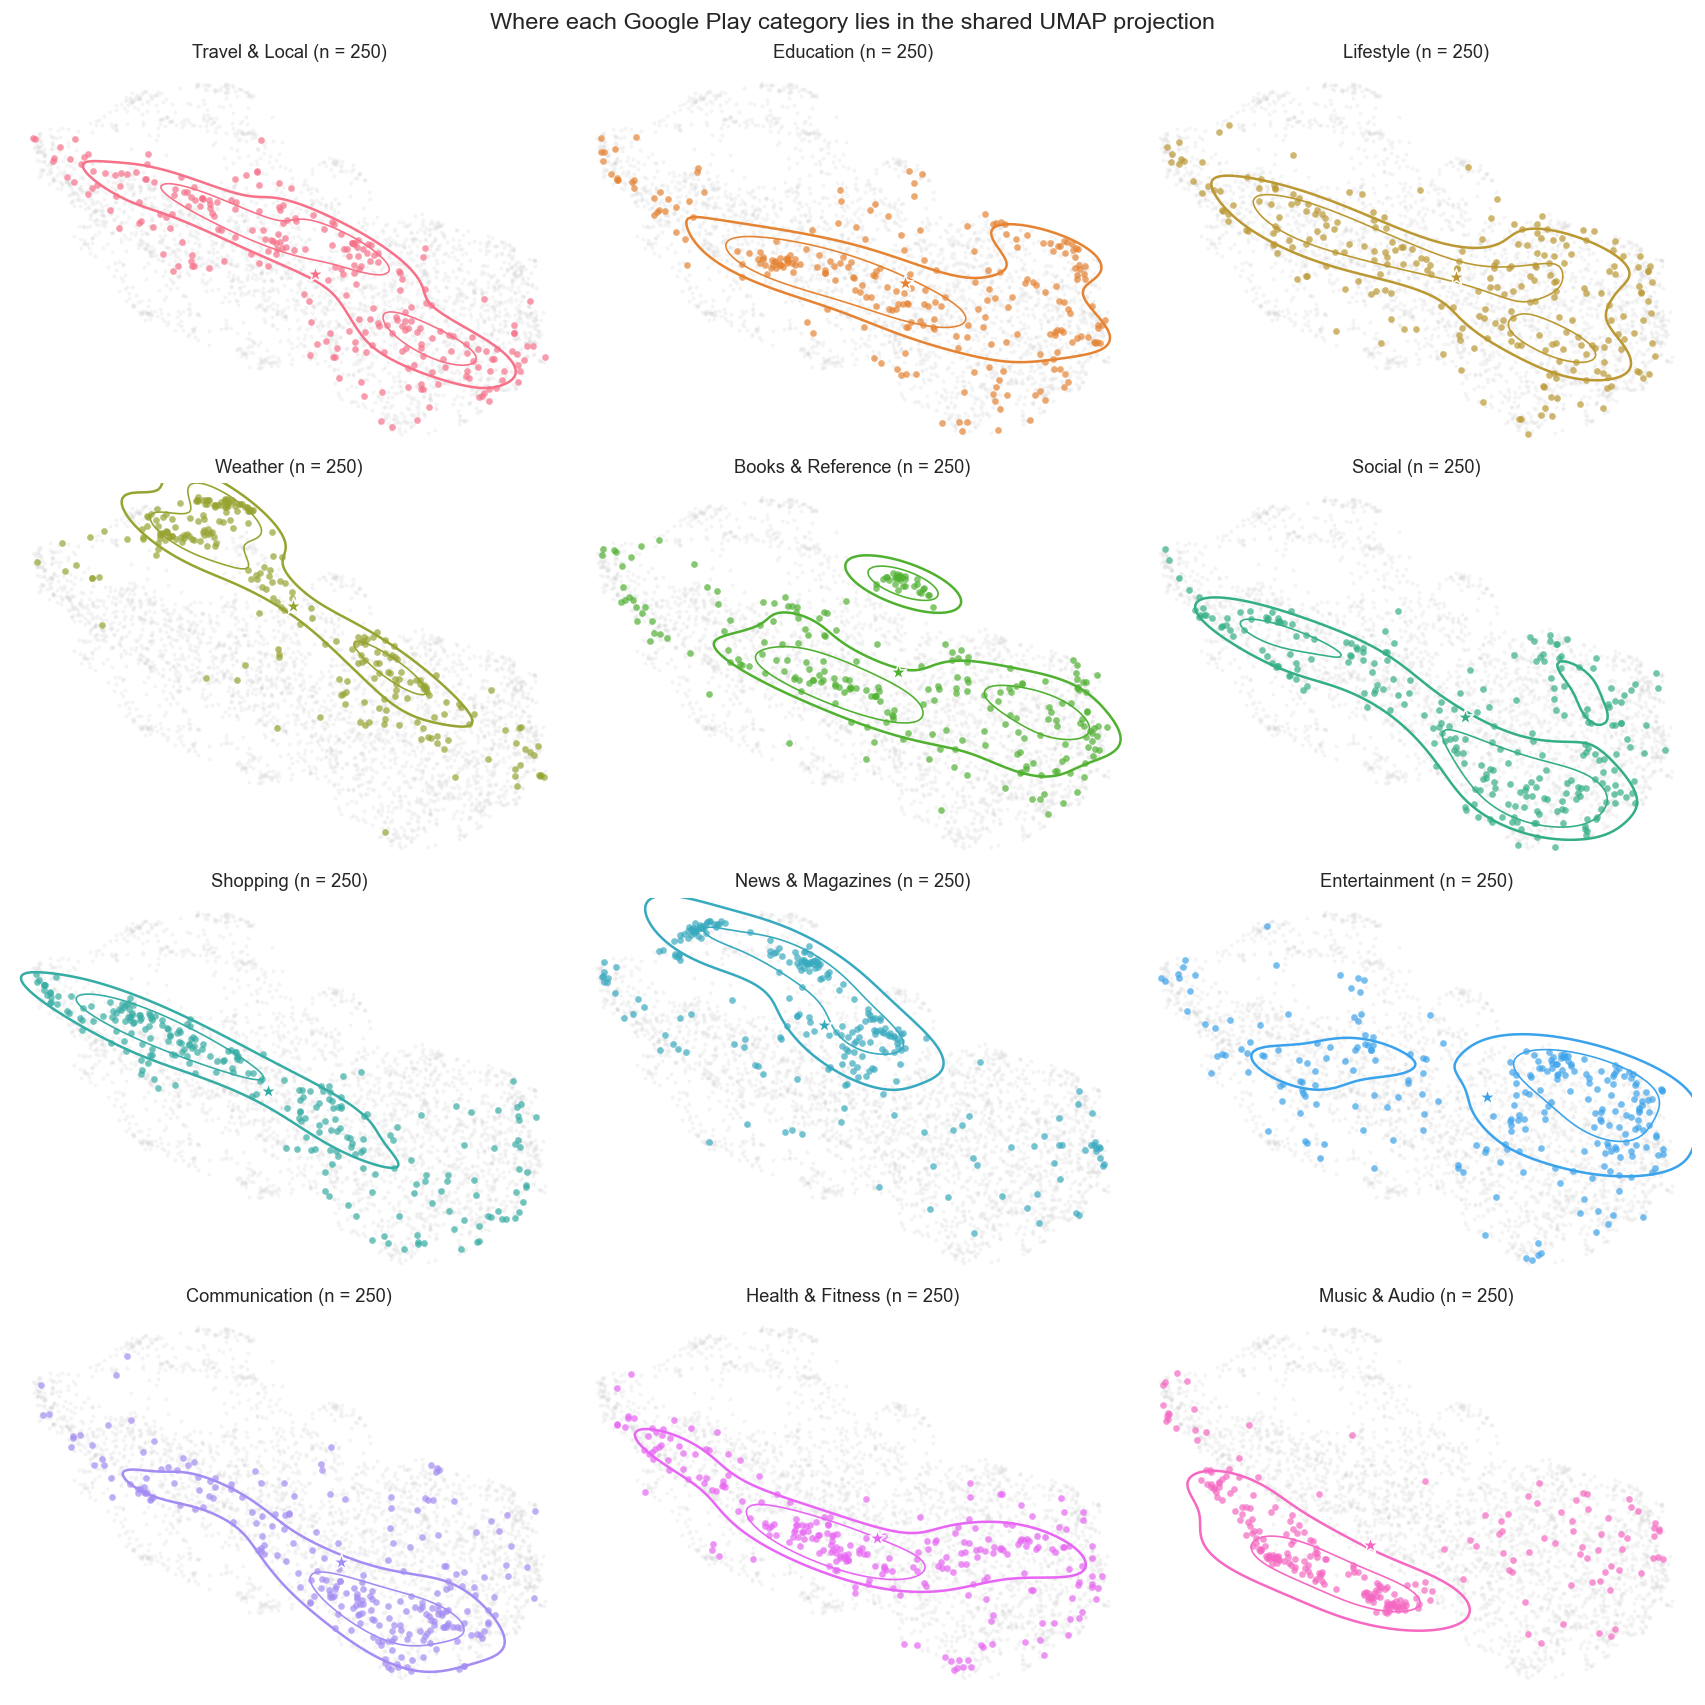

In [9]:
n_cols = 3
n_rows = int(np.ceil(len(category_order) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, 3.25 * n_rows), squeeze=False, constrained_layout=True)
axes = axes.ravel()
x_pad = 0.04 * projection["umap_1"].max() - 0.04 * projection["umap_1"].min()
y_pad = 0.04 * projection["umap_2"].max() - 0.04 * projection["umap_2"].min()
x_limits = (projection["umap_1"].min() - x_pad, projection["umap_1"].max() + x_pad)
y_limits = (projection["umap_2"].min() - y_pad, projection["umap_2"].max() + y_pad)

for ax, category in zip(axes, category_order):
    focus = projection[projection["category"] == category]
    ax.scatter(
        projection["umap_1"], projection["umap_2"], s=5, color="#c7c7c7",
        alpha=0.18, linewidths=0, rasterized=True, zorder=1,
    )
    ax.scatter(
        focus["umap_1"], focus["umap_2"], s=14, color=palette[category],
        alpha=0.68, linewidths=0, rasterized=True, zorder=2,
    )
    if focus["umap_1"].nunique() > 1 and focus["umap_2"].nunique() > 1:
        sns.kdeplot(
            data=focus, x="umap_1", y="umap_2", levels=[0.5, 0.8], thresh=0.05,
            color=palette[category], linewidths=(1.4, 0.9), ax=ax, zorder=3,
        )
    centroid = centroids.loc[category]
    ax.scatter(
        centroid["umap_1"], centroid["umap_2"], marker="*", s=90,
        color=palette[category], edgecolor="white", linewidth=0.8, zorder=4,
    )
    ax.set(title=f"{category} (n = {len(focus)})", xlim=x_limits, ylim=y_limits, xlabel="", ylabel="")
    ax.set_xticks([])
    ax.set_yticks([])
    sns.despine(ax=ax, left=True, bottom=True)

for ax in axes[len(category_order):]:
    ax.remove()
fig.suptitle("Where each Google Play category lies in the shared UMAP projection", fontsize=13)
fig.savefig(OUTPUT_DIR / "app_categories_umap_small_multiples.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "app_categories_umap_small_multiples.pdf", bbox_inches="tight")
plt.show()

## Category neighborhood purity

This is the main category-level comparison because it uses cosine neighbors in the original normalized embedding space, not distances in a two-dimensional projection. The dots show the within-category chance level implied by category size; the dashed line is the overall observed purity.

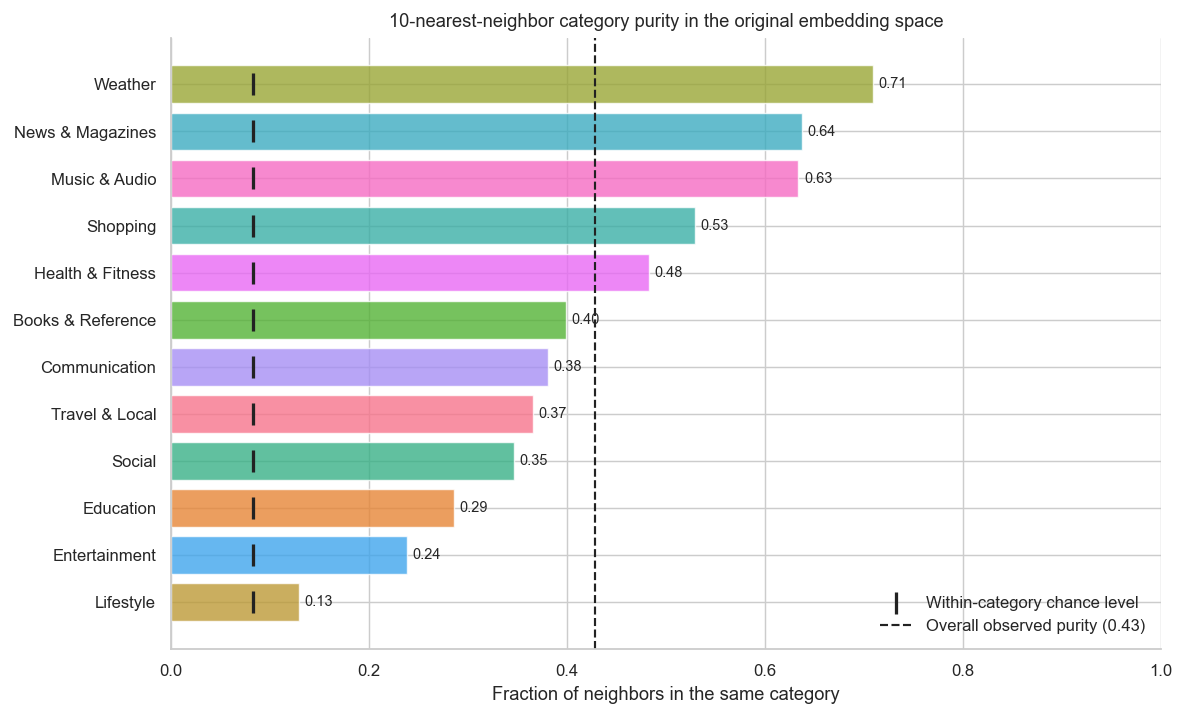

In [10]:
purity_plot = category_metrics.reset_index().sort_values("neighbor_purity")
fig, ax = plt.subplots(figsize=(9, max(5, 0.45 * len(purity_plot))), constrained_layout=True)
bars = ax.barh(
    purity_plot["category"], purity_plot["neighbor_purity"],
    color=[palette[c] for c in purity_plot["category"]], alpha=0.78,
)
ax.scatter(
    purity_plot["chance_purity"], purity_plot["category"], marker="|", s=150,
    color="#222222", linewidth=1.8, label="Within-category chance level", zorder=3,
)
ax.axvline(observed_purity, color="#222222", linestyle="--", linewidth=1.2, label=f"Overall observed purity ({observed_purity:.2f})")
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
ax.set(
    title=f"{k}-nearest-neighbor category purity in the original embedding space",
    xlabel="Fraction of neighbors in the same category", ylabel="", xlim=(0, 1),
)
ax.legend(frameon=False, loc="lower right")
sns.despine(ax=ax)
fig.savefig(OUTPUT_DIR / "category_neighborhood_purity.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "category_neighborhood_purity.pdf", bbox_inches="tight")
plt.show()

## Secondary projection diagnostics

PCA and t-SNE remain useful sensitivity checks, but they are shown separately from the primary UMAP views. PCA preserves linear global variance; t-SNE emphasizes local neighborhoods, so distant island positions should not be interpreted.

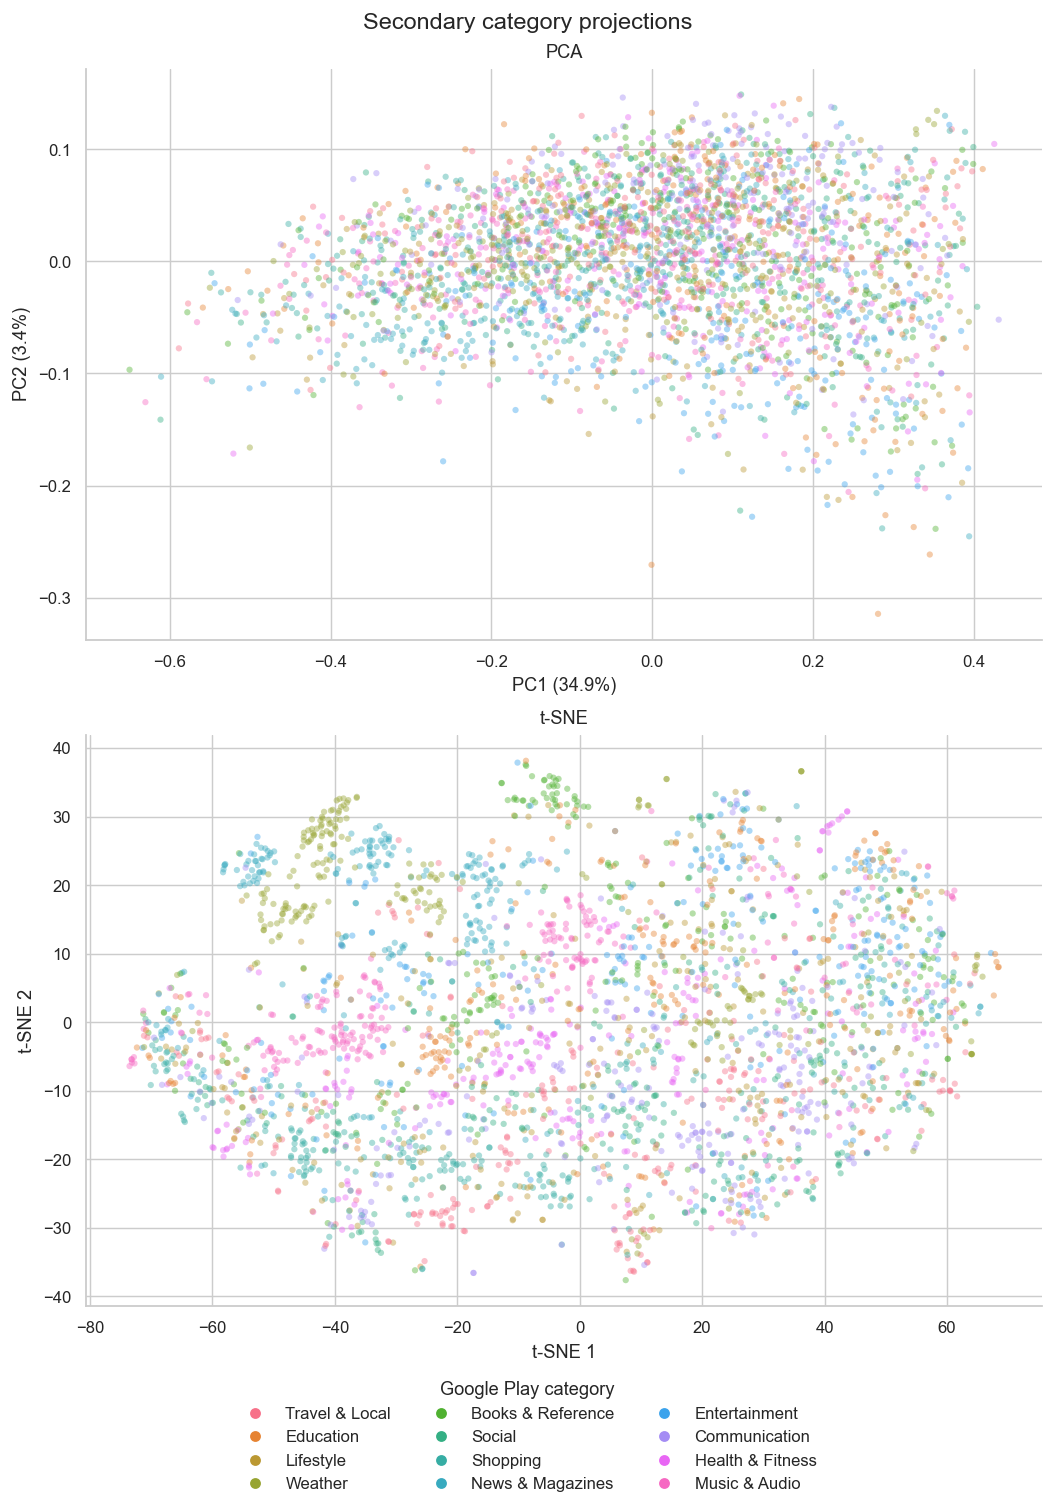

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(8, 11.5), constrained_layout=True)
diagnostics = [
    ("pca_1", "pca_2", "PCA", f"PC1 ({pca_pre.explained_variance_ratio_[0]:.1%})", f"PC2 ({pca_pre.explained_variance_ratio_[1]:.1%})"),
    ("tsne_1", "tsne_2", "t-SNE", "t-SNE 1", "t-SNE 2"),
]
for ax, (x, y, title, xlabel, ylabel) in zip(axes, diagnostics):
    sns.scatterplot(
        data=projection, x=x, y=y, hue="category", hue_order=category_order,
        palette=palette, s=12, alpha=0.42, linewidth=0, ax=ax, legend=False, rasterized=True,
    )
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    sns.despine(ax=ax)

handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=5, color=palette[c], label=c) for c in category_order]
fig.legend(handles=handles, loc="outside lower center", ncol=3, frameon=False, title="Google Play category")
fig.suptitle("Secondary category projections", fontsize=13)
fig.savefig(OUTPUT_DIR / "app_categories_pca_tsne_diagnostics.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "app_categories_pca_tsne_diagnostics.pdf", bbox_inches="tight")
plt.show()

## Reading the result

Evidence for category structure is strongest when neighborhood purity is clearly above both the frequency baseline and permutation distribution, the permutation p-value is small, and the silhouette score is positive. The faceted UMAP shows which categories contribute compact neighborhoods, which overlap, and where outliers occur.

A low PCA explained-variance percentage does not refute local category structure: two linear components may retain little of a high-dimensional embedding. Conversely, visually separated t-SNE or UMAP islands alone are insufficient evidence because both methods can accentuate local gaps. Treat the original-space neighborhood-purity chart and metrics table as the primary evidence, with projections as supporting views.